Doing the the needed formalities

In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("deepu1109/star-dataset")

print("Path to dataset files:", path)

100%|██████████| 3.16k/3.16k [00:00<00:00, 3.14MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/deepu1109/star-dataset/versions/1


In [4]:
import os

# Find any CSV file inside the downloaded path
files = os.listdir(path)
csv_files = [f for f in files if f.endswith('.csv')]

if csv_files:
    csv_path = os.path.join(path, csv_files[0])
    print(f"Loading dataset from: {csv_path}")
    df = pd.read_csv(csv_path)
    print(df.head())
else:
    print(f"No CSV files found in {path}. Available files: {files}")

Loading dataset from: /root/.cache/kagglehub/datasets/deepu1109/star-dataset/versions/1/6 class csv.csv
   Temperature (K)  Luminosity(L/Lo)  ...  Star color  Spectral Class
0             3068          0.002400  ...         Red               M
1             3042          0.000500  ...         Red               M
2             2600          0.000300  ...         Red               M
3             2800          0.000200  ...         Red               M
4             1939          0.000138  ...         Red               M

[5 rows x 7 columns]


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

Checking out the dataset

In [5]:
df.shape

(240, 7)

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 240 entries, 0 to 239
Data columns (total 7 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Temperature (K)         240 non-null    int64  
 1   Luminosity(L/Lo)        240 non-null    float64
 2   Radius(R/Ro)            240 non-null    float64
 3   Absolute magnitude(Mv)  240 non-null    float64
 4   Star type               240 non-null    int64  
 5   Star color              240 non-null    object 
 6   Spectral Class          240 non-null    object 
dtypes: float64(3), int64(2), object(2)
memory usage: 13.3+ KB


In [10]:
df.isnull().sum()

,0
Temperature (K),0
Luminosity(L/Lo),0
Radius(R/Ro),0
Absolute magnitude(Mv),0
Star type,0
Star color,0
Spectral Class,0


In [12]:
df.describe()


,Temperature (K),Luminosity(L/Lo),Radius(R/Ro),Absolute magnitude(Mv),Star type
count,240.000000,240.000000,240.000000,240.000000,240.000000
mean,10497.462500,107188.361635,237.157781,4.382396,2.500000
std,9552.425037,179432.244940,517.155763,10.532512,1.711394
min,1939.000000,0.000080,0.008400,-11.920000,0.000000
25%,3344.250000,0.000865,0.102750,-6.232500,1.000000
50%,5776.000000,0.070500,0.762500,8.313000,2.500000
75%,15055.500000,198050.000000,42.750000,13.697500,4.000000
max,40000.000000,849420.000000,1948.500000,20.060000,5.000000


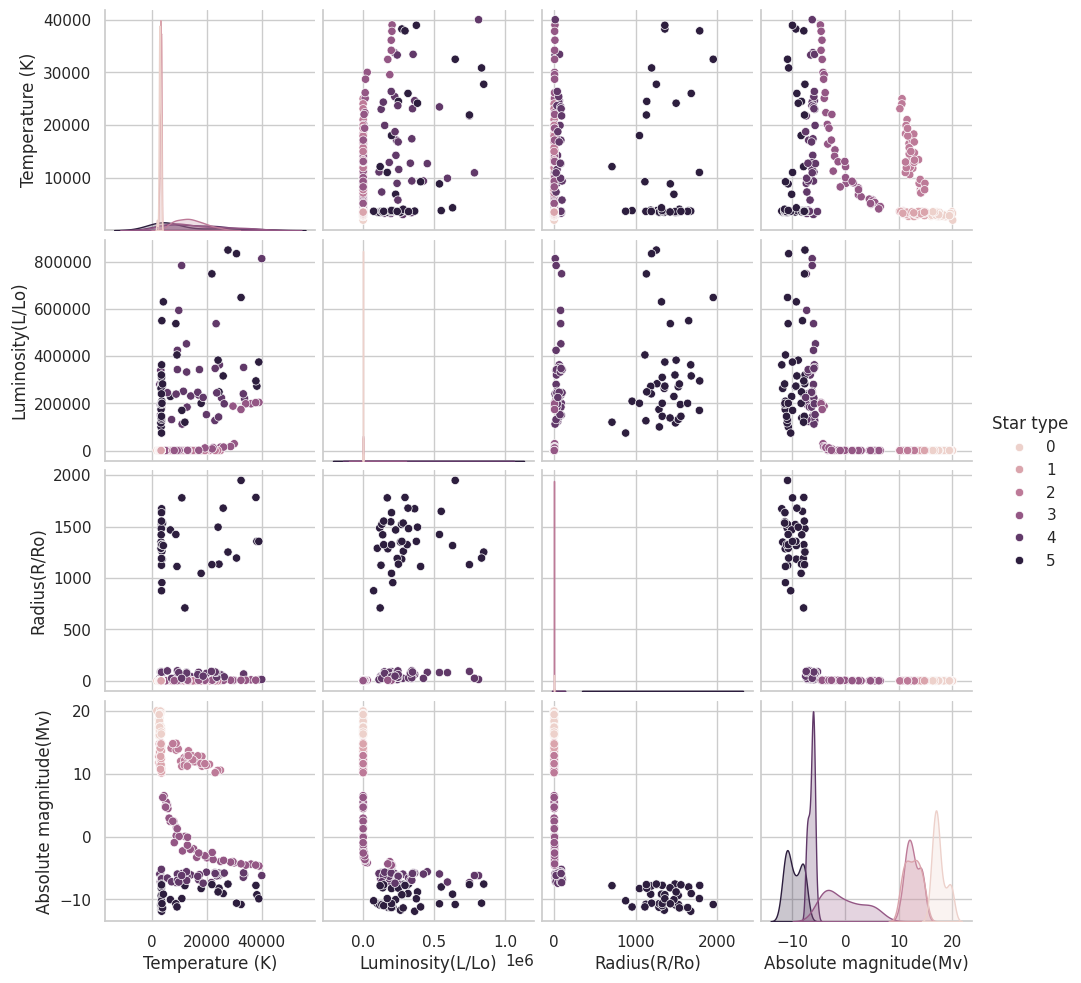

In [29]:
sns.pairplot(df,hue="Star type")
plt.show()

Making HR diagram

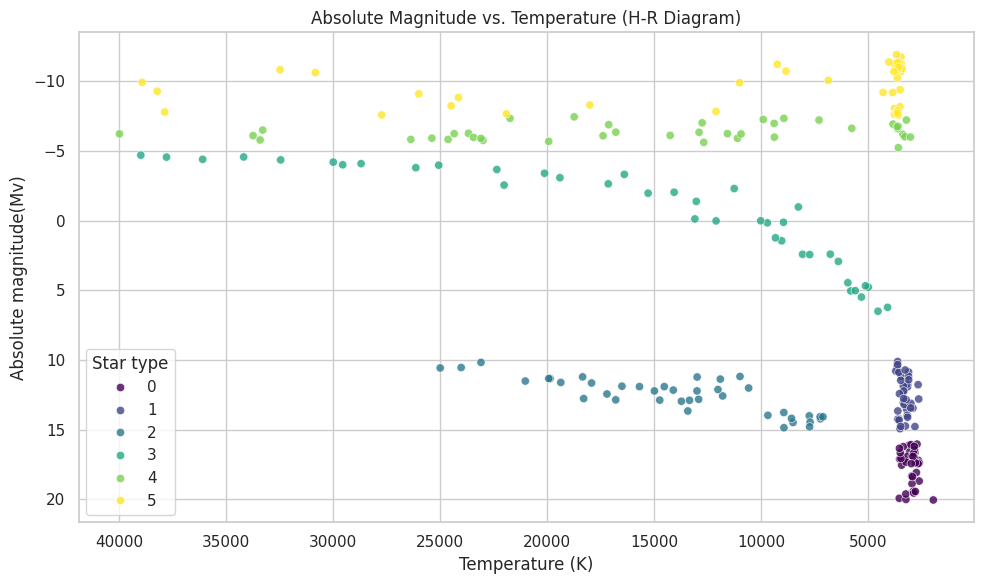

In [36]:
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(10, 6))

# Absolute Magnitude (y-axis) vs Temperature (x-axis)
sns.scatterplot(
    data=df,
    x="Temperature (K)",
    y="Absolute magnitude(Mv)",
    hue="Star type",
    palette="viridis",
    ax=ax,
    alpha=0.8
)
# Temperature is inverted in HR diagrams
ax.invert_xaxis()
# Absolute magnitude is inverted HR diagrams
ax.invert_yaxis()
ax.set_title("Absolute Magnitude vs. Temperature (H-R Diagram)")

plt.tight_layout()
plt.show()

In [38]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

# Prepare features (X) and target (y)
feature_cols = ['Temperature (K)', 'Luminosity(L/Lo)', 'Radius(R/Ro)', 'Absolute magnitude(Mv)']
X = df[feature_cols]
y = df['Star type']

# Split the data into 180 train and 60 test instances
# Total = 240. 60 / 240 = 0.25 (25% test size)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=60, random_state=8, stratify=y
)

print(f"Training set size: {X_train.shape[0]}")
print(f"Testing set size: {X_test.shape[0]}")

Training set size: 180
Testing set size: 60


kNN Accuracy: 96.67%

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       1.00      1.00      1.00        10
           2       1.00      1.00      1.00        10
           3       0.90      0.90      0.90        10
           4       0.90      0.90      0.90        10
           5       1.00      1.00      1.00        10

    accuracy                           0.97        60
   macro avg       0.97      0.97      0.97        60
weighted avg       0.97      0.97      0.97        60



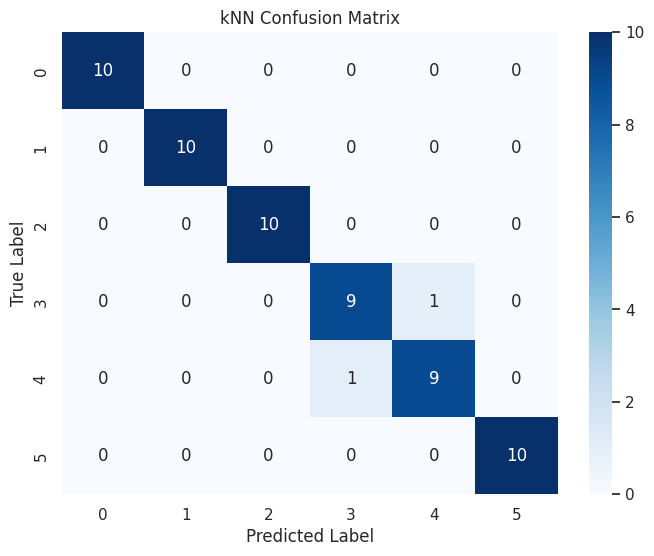

In [39]:
# Normalize the features using StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Train a kNN Classifier
knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(X_train_scaled, y_train)

# Predict on test set
y_pred = knn.predict(X_test_scaled)

# Evaluate the model performance
accuracy = accuracy_score(y_test, y_pred)
print(f"kNN Accuracy: {accuracy * 100:.2f}%\n")
print("Classification Report:")
print(classification_report(y_test, y_pred))

# Plot confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues',
            xticklabels=sorted(y.unique()), yticklabels=sorted(y.unique()))
plt.title('kNN Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()